# **RNN(Recurrent Neural Network, 순환 신경망)**
* 입력과 출력을 시퀀스(Sequence) 단위로 처리하는 가장 기본적인 인공 신경망
* https://wikidocs.net/book/2155

* **머신러닝** 
    - 지도학습 : 회귀/분류
    - 비지도학습 : 군집
* **딥러닝**
    - CNN : 이미지분석
    - RNN : 언어, 시계열

In [1]:
import os
# TensorFlow 안내 및 경고 로그 끄기 (3 = ERROR/FATAL 로그만 표시)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
# oneDNN 최적화 관련 안내 문구 숨기기
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
# absl 라이브러리 초기화 전 경고(WARNING: All log messages...) 숨기기
os.environ['ABSL_LOGGING_MIN_LOG_LEVEL'] = '3'

import warnings
warnings.filterwarnings(action='ignore')

from sklearn import set_config
set_config(display="text")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

import tensorflow as tf
tf.random.set_seed(1234)
np.random.seed(1234)

from sklearn.model_selection import train_test_split   #---- 문제답 분리

from keras.models import Sequential
#from keras.layers import Conv2D, MaxPooling2D  #---- CNN
from tensorflow.keras.layers import SimpleRNN , LSTM, Input  #-----RNN
from keras.layers import Dense, Flatten                      #---- FC

#---------------------- 한글 폰트 지정 -----------------------
plt.rcParams["axes.unicode_minus"] = False                   # 마이너스 기호 깨짐 방지

#plt.rcParams["font.family"] = "Malgun Gothic"               #--------------윈도우 인 경우 
import matplotlib.font_manager as fm                         #--------------리눅스인 경우
font_path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
fm.fontManager.addfont(font_path)
font_prop = fm.FontProperties(fname=font_path)
plt.rcParams["font.family"] = font_prop.get_name()


## **[3-3] 신경망 언어 모델**

### RNN(Recurrent Neural Network) : 순환 신경망

<img src="https://static.wikidocs.net/images/page/22886/rnn_image2_ver3.PNG" width=300>

<table border=0>
    <tr><td><img src="https://wikidocs.net/images/page/22886/rnn_image4_ver2.PNG"></td>
        <td><img width=200 src="https://wikidocs.net/images/page/22888/vanilla_rnn_ver2.PNG"></td></tr></table><br>
입력층 : $h_{t} = tanh(W_{x} x_{t} + W_{h}h_{t−1} + b)$        <br>
출력층 : $y_{t} = f(W_{y}h_{t} + b)$ <br><br>
<img src="https://wikidocs.net/images/page/22886/rnn_images4-5.PNG">

* 3D : (batch_size, timesteps, input_dim) 덩어리,행,렬
* model.add(SimpleRNN(hidden_units, input_shape=(timesteps=행수, input_dim=열수)))
* model.add(SimpleRNN(hidden_units, input_length=행수, input_dim=열수))
* return_sequences = True

<img src="https://static.wikidocs.net/images/page/22886/rnn_image6between7.PNG" width=300>

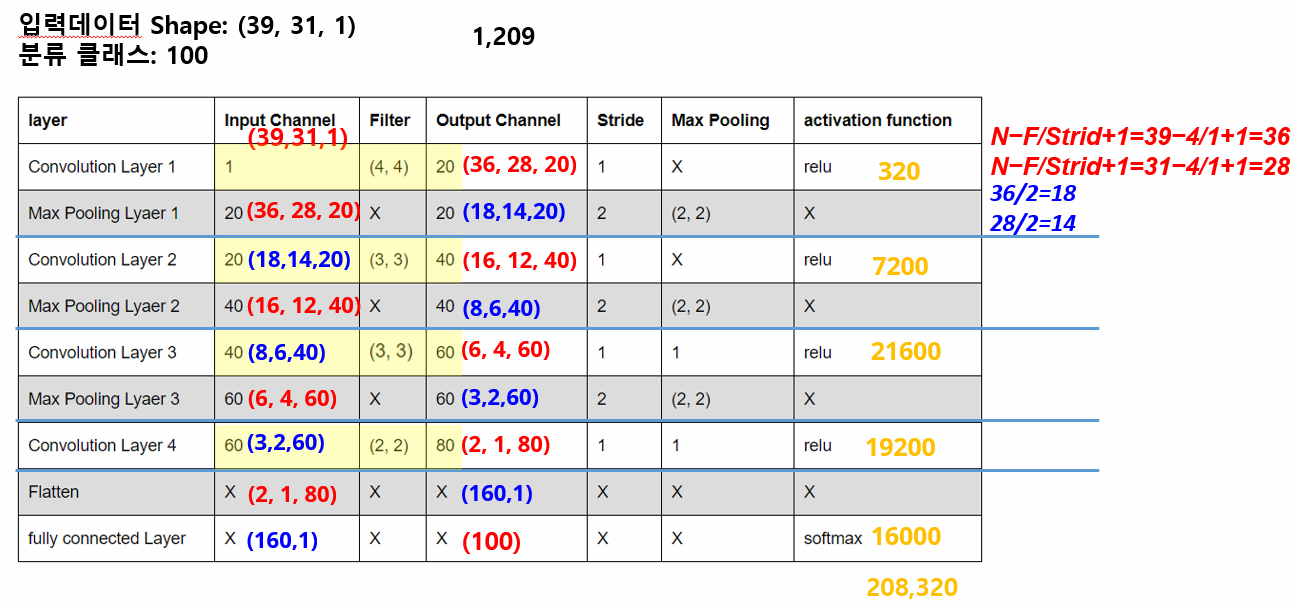

In [2]:
model = Sequential( [
    SimpleRNN(3, input_shape=(2,10) )
])
model.summary()

# model = Sequential()
# model.add(SimpleRNN(3, input_shape=(2,10)))
# # model.add(SimpleRNN(3, input_length=2, input_dim=10))와 동일함.
# model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 3)              │            42 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 42 (168.00 B)

 Trainable params: 42 (168.00 B)

 Non-trainable params: 0 (0.00 B)

### LSTM(Long Short-Term Memory) : 장단기 메모리
* 기존 RNN의 기울기 소실 문제를 해결하기 위해 게이트(Gate) 메커니즘을 도입한 순환 신경망(RNN) 모델
* LSTM(단방향), BiLSTM(양방향)

<img src="https://static.wikidocs.net/images/page/22888/vaniila_rnn_and_different_lstm_ver2.PNG" width=300>

<table>
<tr>
<td>
    <b>Step 1. Forget Gate: 과거 정보를 버릴지 말지 결정하는 과정<br>
    <img src="https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Ft1.daumcdn.net%2Fcfile%2Ftistory%2F99B7AA385C30F68708" width=600></td>
<td>
    <b>Step 2. Input Gate: 현재 정보를 저장할지 결정하는 과정<br>
    <img src="https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Ft1.daumcdn.net%2Fcfile%2Ftistory%2F99AE0E485C30F68705" width=600></td>
</tr>
<tr>    
    <td>
        <b>Step 3. Update (cell state): 과거 cell state(Ct-1)를 새로운 state(Ct)로 업데이트 하는 과정<br>
        <img src="https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Ft1.daumcdn.net%2Fcfile%2Ftistory%2F99A8453C5C30F68708" width=600></td>
<td>   
    <b>Step 4. Output Gate (hidden state): 어떤 출력값을 출력할지 결정하는 과정<br>
    <img src="https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Ft1.daumcdn.net%2Fcfile%2Ftistory%2F99987F375C30F68706" width=600></td>
</tr>
</table>    

<pre>
학습 데이터셋       : data = [1,2,3,4,5,6,7,8,9,10]
<font color=red><b>LSTM 모델 생성      : 단방향   many-to-one   다층</b></font>
모델 컴파일         : loss='mse', optimizer='adam‘
학습               : epochs=50, batch_size=2
train , test 분리  : 7:3
    
텐서 구성           : <font color=red><b>X:(None,2,5) y:1</b></font>
 X                      y
     ---------        --------
     1,2,3,4,5          6
     2,3,4,5,6          7 … 생략
X=  [
       [[1],[2],[3],[4],[5]] ,
       [[2],[3],[4],[5],[6]]
    ]
y=  [6, 7, 8, 9, 10] 
예측,결과 시각화

#### 데이터 가공 (윈도우 슬라이딩)

In [3]:
def MY_WINDOW_SLIDING(data,  window_size=5, feature_dim=1) :
    data_size = len(data)
    loop_cnt = data_size - window_size
    #print("loop_cnt = data_size - window_size", loop_cnt)
    
    X_list = []
    y_list = []
    for i in range(loop_cnt ) : 
        X_list.append( data[i : i+window_size] )
        y_list.append( data[i+window_size]     )
   
    X = np.array(X_list).reshape(-1, window_size, feature_dim)
    y = np.array(y_list)
    #print(X)
    #print(y)
    return X, y

In [4]:
data = [1,2,3,4,5,6,7,8,9,10]
X, y = MY_WINDOW_SLIDING(data, window_size=5)
X.shape, y.shape

((5, 5, 1), (5,))

In [5]:
data = list( range(1, 21) )
X, y = MY_WINDOW_SLIDING(data, window_size=5)
X.shape, y.shape

((15, 5, 1), (15,))

In [6]:
data = [[1,99], [2,99], [3,99], [4,99], [5,99], [6,99], [7,99], [8,99], [9,99], [10,99]]
X, y = MY_WINDOW_SLIDING(data, window_size=5, feature_dim=2)
X.shape, y.shape

((5, 5, 2), (5, 2))

#### 8 : 2 분리

In [7]:
int(np.ceil(12.6))

13

In [8]:
int(  np.ceil( len(data) * 0.8 ) )

8

In [9]:
X_train = data[     : int(  np.ceil( len(data) * 0.8 ) )  ]
X_test =  data[ int(  np.ceil( len(data) * 0.8 ) )  :     ]
len(X_train)  , len(X_test)

(8, 2)

In [10]:
X_train, X_test = train_test_split(data, test_size=.2)
len(X_train)  , len(X_test)

(8, 2)

#### 모델 생성, 컴파일, 학습

In [11]:
model = Sequential([
    # Input(shape=(5,1)) ,
    # LSTM(8, return_sequences=True) ,
    LSTM(8, return_sequences=True, input_shape=(5,1) ) ,
    LSTM(4) ,
    Dense(1)
])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 5, 8)           │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 4)              │           208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 533 (2.08 KB)

 Trainable params: 533 (2.08 KB)

 Non-trainable params: 0 (0.00 B)

```python
# 모델 컴파일         : loss='mse', optimizer='adam‘
model.compile(loss='mse', optimizer='adam', metrics=["mse"])

# 7 : 3

#학습               : epochs=50, batch_size=2
model.fit(X_train, y_train, epochs=50, batch_size=2, validation_data=(X_val, y_val))

### GRU(Gated Recurrent Unit) : 게이트 순환 유닛
* 기존 RNN의 기울기 소실 문제를 해결하기 위해 게이트(Gate) 메커니즘을 도입한 순환 신경망(RNN) 모델
* LSTM 게이트 연산량을 보안하기위해 2개 게이트 사용
* **리셋 게이트 (Reset Gate)**
    - 과거 정보를 얼마나 무시하고 새로 들어오는 입력과 조합할지 결정
* **업데이트 게이트 (Update Gate)**
    - LSTM의 망각 게이트와 입력 게이트가 합쳐진 형태
    - 이전 상태를 얼마나 유지하고 새로운 상태로 덮어쓸지 한 번에 제어

<table>
<tr>
    <td><img src="https://static.wikidocs.net/images/page/22889/gru.PNG" width=300></td>
    <td>
        $r_{t}=σ(W_{xr}x_{t}+W_{hr}h_{t-1}+b_{r})$<br>
        $z_{t}=σ(W_{xz}x_{t}+W_{hz}h_{t-1}+b_{z})$<br>
        $g_{t}=tanh(W_{hg}(r_{t}∘h_{t-1})+W_{xg}x_{t}+b_{g})$<br>
        $h_{t}=(1-z_{t})∘g_{t}+z_{t}∘h_{t-1}$
    </td>
</tr>
</table>

# **[실습] : 날씨 예측**
* https://data.kma.go.kr/stcs/grnd/grndTaList.do?pgmNo=70
* seoul_temp_sample.csv

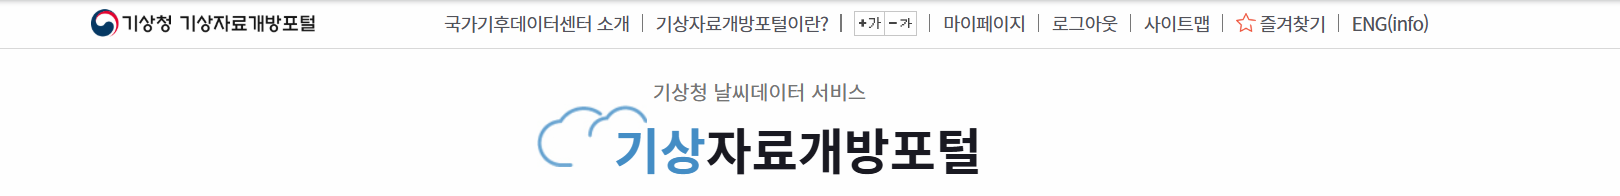

In [12]:
df = pd.read_csv("../datas/seoul_temp_sample.csv", parse_dates=['rdate'])
df.head(1)

,rdate,atemp,ltemp,htemp
0,2026-01-01,-7.4,-10.5,-2.1


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 273 entries, 0 to 272
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   rdate   273 non-null    datetime64[us]
 1   atemp   273 non-null    float64       
 2   ltemp   273 non-null    float64       
 3   htemp   273 non-null    float64       
dtypes: datetime64[us](1), float64(3)
memory usage: 8.7 KB


In [14]:
df.tail(5)

,rdate,atemp,ltemp,htemp
268,2026-09-26,21.9,18.2,27.5
269,2026-09-27,22.4,17.4,28.8
270,2026-09-28,21.2,18.3,26.2
271,2026-09-29,20.9,14.5,27.7
272,2026-09-30,21.6,16.6,27.9


### EDA

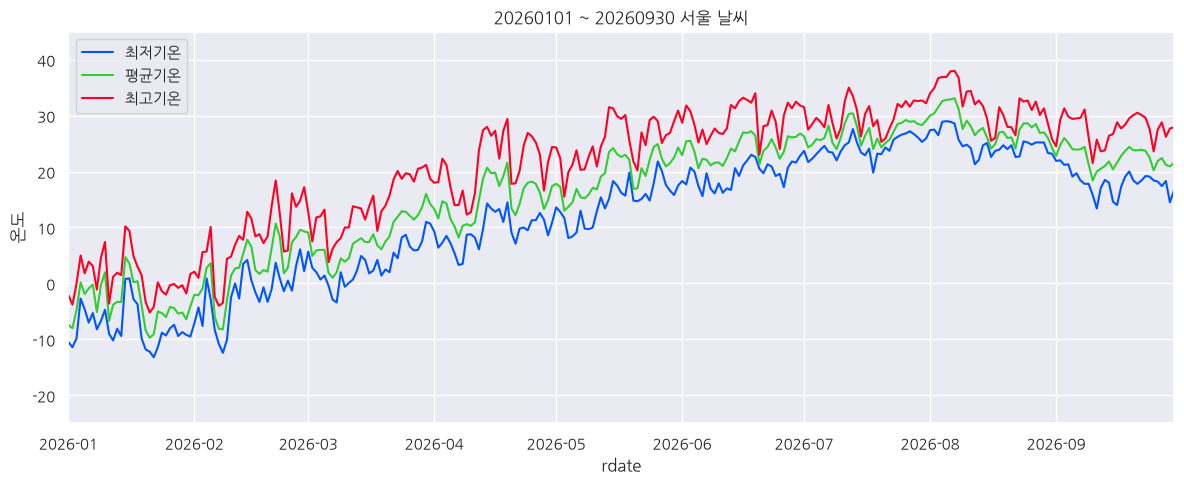

In [15]:
plt.figure(figsize=(12, 5))

# 각 기온 선 그래프 그리기 (이미지 색상 매칭: 최저=블루, 평균=그린, 최고=레드)
sns.lineplot(data=df, x="rdate", y="ltemp", color="#0055ff",  label="최저기온")
sns.lineplot(data=df, x="rdate", y="atemp", color="#33cc33", label="평균기온")
sns.lineplot(data=df, x="rdate", y="htemp", color="#ff0022",  label="최고기온")


plt.title("20260101 ~ 20260930 서울 날씨")
plt.ylabel("온도")

# 축 범위 지정 
plt.ylim(-25, 45)
plt.xlim(df["rdate"].min(), df["rdate"].max())
plt.legend()

plt.tight_layout()
plt.show()

### 전처리 가공
* 데이터 : 윈도우 슬라이딩

In [16]:
df = df.set_index('rdate')
df.head(1)

,atemp,ltemp,htemp
rdate,,,
2026-01-01,-7.4,-10.5,-2.1


* **by JKH**
* X1 shape: (샘플수, 5, 1), y1 shape: (샘플수, 5) 

In [17]:
X1,y1 = MY_WINDOW_SLIDING(df['atemp'].values,  window_size=5, feature_dim=1) 
X1.shape, y1.shape

((268, 5, 1), (268,))

In [18]:
X3,y3 = MY_WINDOW_SLIDING(df.values,  window_size=5, feature_dim=3) 
X3.shape, y3.shape

((268, 5, 3), (268, 3))

### LSTM 모델 구축

In [19]:
model = Sequential([
    LSTM(8,  return_sequences=True, activation='tanh', input_shape=(5,1) ) ,
    LSTM(16, return_sequences=True, activation='tanh') ,
    LSTM(4, activation='tanh') ,
    Dense(1) #----Dense(5) 5일예측
])
model.compile(loss='mse', optimizer='adam', metrics=[tf.keras.metrics.RootMeanSquaredError(name='rmse')])
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 5, 8)           │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 5, 16)          │         1,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 4)              │           336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261 (8.83 KB)

 Trainable params: 2,261 (8.83 KB)

 Non-trainable params: 0 (0.00 B)

### 스케일링

In [20]:
X1.shape,   X1.reshape(-1, 1).shape

((268, 5, 1), (1340, 1))

In [21]:
y1.shape,  y1.reshape(-1,1).shape

((268,), (268, 1))

In [22]:
from sklearn.preprocessing import StandardScaler
X_scaler = StandardScaler()
y_scaler = StandardScaler()

X1_scale = X_scaler.fit_transform(X1.reshape(-1, 1))   #--------오직 2차만 학습가능 (3D --> 2D로 잠시 바꿔 스케일링)
y1_scale = y_scaler.fit_transform(y1.reshape(-1, 1)) 

X1_scale =  X1_scale.reshape(-1, 5,1)  
y1_scale =  y1_scale.reshape(-1)   #---------(-1,5)5일치

In [23]:
X1_scale.shape, y1_scale.shape

((268, 5, 1), (268,))

In [24]:
X1_scale[0], y1_scale[:3]

(array([[-2.14098453],
        [-2.19553726],
        [-1.89549722],
        [-1.44998321],
        [-1.64091778]]),
 array([-1.60159873, -1.53687792, -1.98992364]))

In [25]:
len(X1)

268

### train(8:2) / test 분리
<pre><font size=2>
                          X1 (269건)   
                            |
                        스케일링 (269건)
                            |
           |-------------------------------|
      (학습용 268건)                (테스트 1건)                                              
     X1_train, y1_train             X1_test  --> pred (스케일링된 데이터)  1.7  --> 26(스케일링 원복)
              |                     y1_test  --> 정답지(스케일링된 데이터)  1.85 --> 29(스케일링 원복)
              |
 (학습용 216건)  (자체검증용 54건)
      X8,y8         X2,y2   

In [26]:
print(len(X1_scale), len(y1_scale))

268 268


In [27]:
X1_train = X1_scale[ : -1]
X1_test  = X1_scale[-1 : ]
y1_train = y1_scale[ : -1]
y1_test  = y1_scale[-1 : ]

print(len(X1_train) , len(X1_test),  len(y1_train), len(y1_test))
print(y1_test)

267 1 267 1
[0.47871325]


In [28]:
X8,X2,y8,y2 = train_test_split(X1_train,y1_train, test_size=0.2, shuffle=False)


### 모델 생성 & 학습

In [29]:
fit_res = model.fit(X8, y8, epochs=50, batch_size=10, validation_data=(X2, y2))

Epoch 1/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.9982 - rmse: 0.9991 - val_loss: 0.6385 - val_rmse: 0.7991
Epoch 2/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.7520 - rmse: 0.8672 - val_loss: 0.5464 - val_rmse: 0.7392
Epoch 3/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.4461 - rmse: 0.6679 - val_loss: 0.3173 - val_rmse: 0.5633
Epoch 4/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2205 - rmse: 0.4696 - val_loss: 0.1192 - val_rmse: 0.3452
Epoch 5/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1505 - rmse: 0.3879 - val_loss: 0.0628 - val_rmse: 0.2505
Epoch 6/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1382 - rmse: 0.3718 - val_loss: 0.0550 - val_rmse: 0.2345
Epoch 7/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1336 - rmse: 0.3655 - val_loss: 0.0517 - val_rmse: 0.2274
Epoch 8/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1303 - rmse: 0.3610 - val_loss: 0.0489 - val_rmse: 0.2211
Epoch 9/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - los

### 평가 시각화

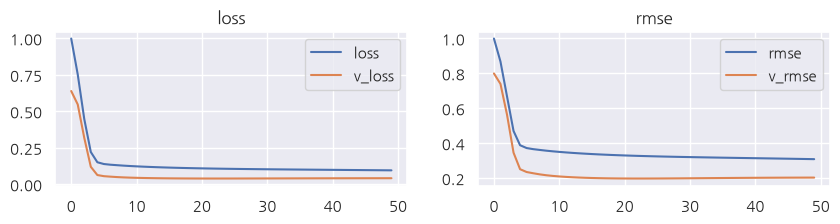

In [30]:
plt.figure(figsize=(10,2))
ax1 = plt.subplot(1,2,1)
ax1.plot(fit_res.history['loss']   ,   label="loss")
ax1.plot(fit_res.history['val_loss'],  label="v_loss")
ax1.legend()
ax1.set_title("loss")

ax2 = plt.subplot(1,2,2)
ax2.plot(fit_res.history['rmse']   ,   label="rmse")
ax2.plot(fit_res.history['val_rmse'],  label="v_rmse")
ax2.legend()
ax2.set_title("rmse")

plt.show()

### test 예측

In [31]:
from sklearn.metrics import root_mean_squared_error

pred = model.predict(X1_test)
print(pred, y1_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 235ms/step
[[0.5096265]] [0.47871325]


In [32]:
pred    = y_scaler.inverse_transform(pred)       #-------2D : 스케일링 된 예측값 점수 내기전 원복
y1_test = y_scaler.inverse_transform([y1_test])  #-------2D : 스케일링 된 정답값 점수 내기전 원복

In [33]:
print(pred, y1_test)

[[21.93435]] [[21.6]]


In [34]:
rmse = root_mean_squared_error(y1_test, pred)
print(f"RMSE : {rmse:.4f}")

RMSE : 0.3343


# --------------------------------

# **[4] 워드 임베딩(Word Embedding)**
* 워드투벡터(Word2Vec)
* 글로브(GloVe)
* 패스트텍스트(FastText)
* 엘모(Embeddings from Language Model, ELMo)

## 워드투벡터(Word2Vec)

## 글로브(GloVe)

# **[5] 토픽 모델링(Topic Modeling)**

## 잠재 디리클레 할당(Latent Dirichlet Allocation, LDA)
* 추천엔진 : NetFlex

## 모델 기반 추천

# **[실습]**
* 감성분석
* 뉴스분석
* 댓글/리뷰 분석
* 추천엔진
* 텍스트 요약(Text Summarization)
* 챗봇